# Zomato Exploratory Data Analysis Project

### Installing Matplotlib & Seaborn Library

In [2]:
!pip install Matplotlib

In [3]:
!pip install seaborn

### Importing all the requrired Libraries

In [7]:
%pip show matplotlib

Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install matplotlib seaborn

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

## loading tha dataset

In [5]:
df = pd.read_csv("Zomato EDA Project/zomato_data.csv")

In [26]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [27]:
df.shape

(148, 7)

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   restaurant name              148 non-null    str  
 1   online_order                 148 non-null    str  
 2   book_table                   148 non-null    str  
 3   rate                         148 non-null    str  
 4   votes                        148 non-null    int64
 5   approx_cost(for two people)  148 non-null    int64
 6   listed_in(type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 8.2 KB


In [29]:
df.describe

<bound method NDFrame.describe of            restaurant name online_order book_table   rate  votes  \
0                    Jalsa          Yes        Yes  4.1/5    775   
1           Spice Elephant          Yes         No  4.1/5    787   
2          San Churro Cafe          Yes         No  3.8/5    918   
3    Addhuri Udupi Bhojana           No         No  3.7/5     88   
4            Grand Village           No         No  3.8/5    166   
..                     ...          ...        ...    ...    ...   
143       Melting Melodies           No         No  3.3/5      0   
144        New Indraprasta           No         No  3.3/5      0   
145           Anna Kuteera          Yes         No  4.0/5    771   
146                 Darbar           No         No  3.0/5     98   
147          Vijayalakshmi          Yes         No  3.9/5     47   

     approx_cost(for two people) listed_in(type)  
0                            800          Buffet  
1                            800          Buffe

## Data Cleaning & Preparation

## 1 Convert the Rate Column to a Numeric Data type

In [31]:
def handlerate(value):
    value = str(value).split('/')
    value = value[0]
    return float(value)
df ['rate'] = df ['rate'].apply(handlerate)
print(df.head(5))

         restaurant name online_order book_table  rate  votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   approx_cost(for two people) listed_in(type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   restaurant name              148 non-null    str    
 1   online_order                 148 non-null    str    
 2   book_table                   148 non-null    str    
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 8.2 KB


## Standardize Column Names

In [33]:
df.columns = df.columns.str.lower()

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   restaurant name              148 non-null    str    
 1   online_order                 148 non-null    str    
 2   book_table                   148 non-null    str    
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 8.2 KB


In [35]:
df.columns

Index(['restaurant name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost(for two people)', 'listed_in(type)'],
      dtype='str')

### Rename the cost column

In [36]:
df. rename(
    columns = {'approx_cost(for two people)': 'approx_cost'},
    inplace = True
)

In [37]:
df.columns

Index(['restaurant name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost', 'listed_in(type)'],
      dtype='str')

## Checking for Missing values and Duplicate Recoards

In [38]:
print("Missing value:")
print(df.isnull().sum())
print("Duplicate Rows:",df.duplicated().sum())

Missing value:
restaurant name    0
online_order       0
book_table         0
rate               0
votes              0
approx_cost        0
listed_in(type)    0
dtype: int64
Duplicate Rows: 0


## Exploratory Data Analysis

1. How many customer votes has each restaurant type received?
2. How many restaurants offer table booking?
3. Which five restaurants have the highest number of votes?
4. Is there a relationship between restaurant ratings and customer votes?
5. What is the average rating for each restaurant type?
6. What type of restaurant do the majority of customers order from?
7. What ratings do restaurants most commonly receive?
8. Which restaurant type has the highest average cost for two people?
9. Which order mode - online or offline - gets better ratings?
10.Which restaurant types have more offline-ordering records?

## 1. How many customer votes has each restaurant type received?


In [39]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [40]:
 grouped_data = df.groupby('listed_in(type)')['votes'].sum()
 grouped_data

listed_in(type)
Buffet     3028
Cafes      6434
Dining    20363
other      9367
Name: votes, dtype: int64

### 2. How many restaurants offer table booking?


In [41]:
result = df['book_table'].value_counts()
result

book_table
No     140
Yes      8
Name: count, dtype: int64

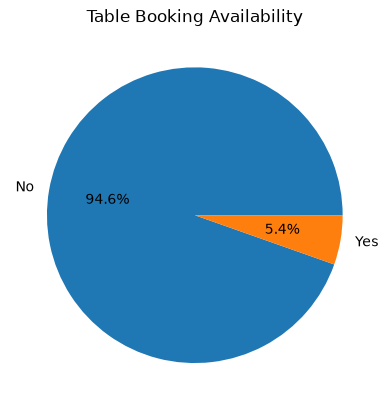

In [44]:
result.plot.pie(autopct = '%1.1f%%')
plt.title("Table Booking Availability")
plt.show()

### 3. Which five restaurants have the highest number of votes?


In [45]:
top5 = df.nlargest(5, 'votes')
print(top5[['restaurant name', 'votes']])

      restaurant name  votes
38  Empire Restaurant   4884
86      Meghana Foods   4401
7              Onesta   2556
44             Onesta   2556
65        Kabab Magic   1720


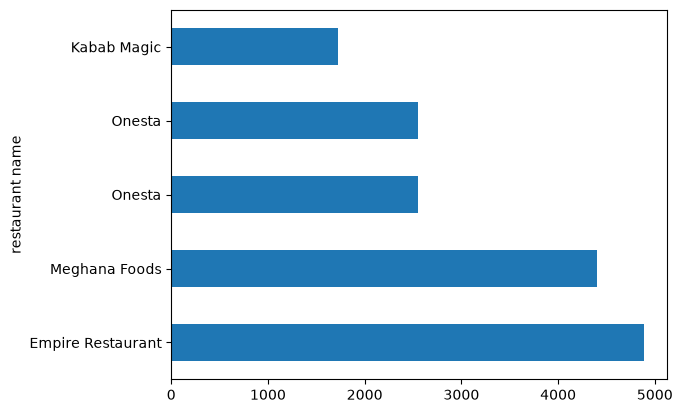

In [47]:
top5.plot.barh(x= 'restaurant name', y = 'votes' , legend = False)
plt.show()

### 4. Is there a relationship between restaurant ratings and customer votes?


In [48]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


<function matplotlib.pyplot.show(close=None, block=None)>

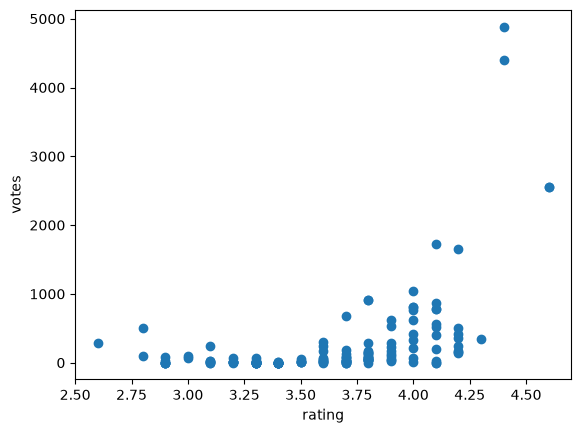

In [54]:
plt.scatter(df['rate'], df ['votes'])
plt.xlabel("rating")
plt.ylabel("votes")
plt.show

### 5. What is the average rating for each restaurant type?


In [56]:
result = df.groupby('listed_in(type)')['rate'].mean()
print(result.sort_values(ascending=False))

listed_in(type)
other     3.912500
Buffet    3.842857
Cafes     3.765217
Dining    3.571818
Name: rate, dtype: float64


### 6. What type of restaurant do the majority of customers order from?


Text(0, 0.5, 'Count of Restaurant')

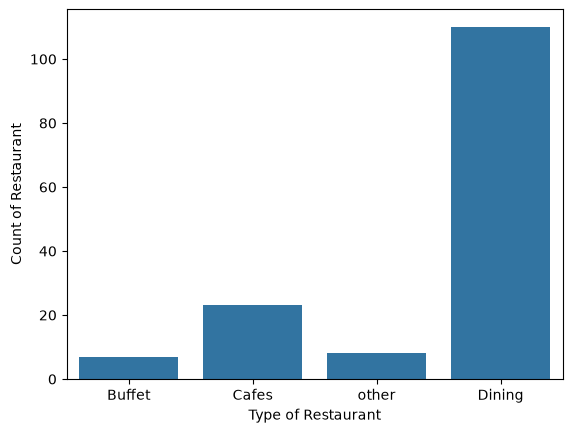

In [60]:
sns.countplot(x=df['listed_in(type)'])
plt.xlabel("Type of Restaurant")
plt.ylabel("Count of Restaurant")

### 7. What ratings do restaurants most commonly receive?


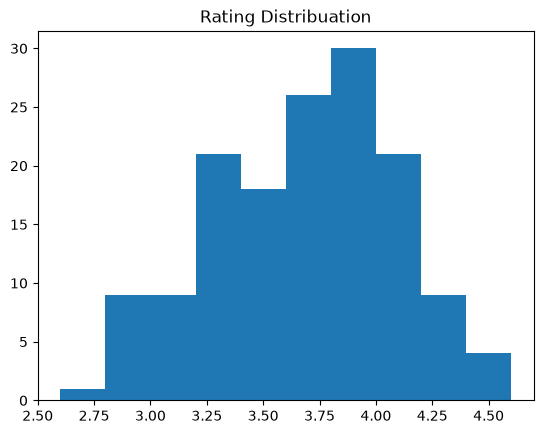

In [63]:
plt.hist(df['rate'], bins = 10)
plt.title("Rating Distribuation")
plt.show()

### 8. Which restaurant type has the highest average cost for two people?


In [65]:
result = df.groupby('listed_in(type)')['approx_cost'].mean()
result.sort_values(ascending = False)

listed_in(type)
Buffet    671.428571
other     668.750000
Cafes     545.652174
Dining    357.272727
Name: approx_cost, dtype: float64

### 9. Which order mode - online or offline - gets better ratings?


In [66]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


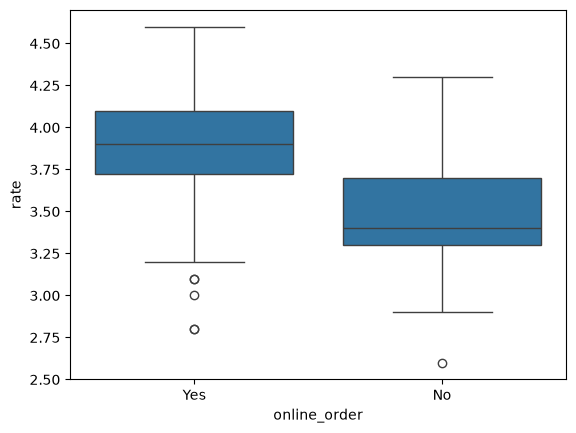

In [67]:
sns.boxplot(x ='online_order', y = 'rate', data = df)
plt.show() 

### 10.Which restaurant types have more offline-ordering records?

In [71]:
pivot_table = df.pivot_table(
    index = 'listed_in(type)',
    columns = 'online_order',
    aggfunc ='size',
    fill_value = 0)

"pivot_table

online_order,No,Yes
listed_in(type),,
Buffet,3,4
Cafes,8,15
Dining,77,33
other,2,6


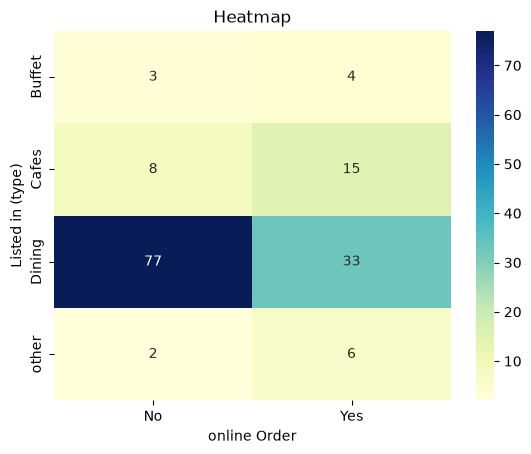

In [75]:
sns.heatmap(
    pivot_table, annot = True, cmap = "YlGnBu", fmt = 'd')
plt.title("Heatmap")
plt.xlabel("online Order")
plt.ylabel("Listed in (type)")
plt.show()